## Author: Gabriel Vance
## Class: DSC550 - Data Mining
## Professor: Dr. Brett Werner
## Date: June 9, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 2 of the class. Data must be present within the folder that this notebook is run in.
# This week focuses on Graph Analysis with Matplotlib

## 2.2 Exercise: Graph Analysis with Matplotlib
 

In [1]:
# impports
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns

### Using a data set of your choice, write an introduction explaining the data set.

In [2]:
#! Data can be downloaded from Kaggle using the kagglehub package.
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("jacksoncrow/stock-market-dataset")

# print("Path to dataset files:", path)
df = pd.read_csv("O.csv")

print("This dataset was sourced from Kaggle and focuses on a single stock: Realty Income Corporation (ticker symbol: O). It contains daily trading information, with each row representing one trading day. The dataset includes the following columns: Date, Open, High, Low, Close, Adjusted Close, and Volume. It's a straightforward time series dataset that tracks the stock’s performance over time.")

This dataset was sourced from Kaggle and focuses on a single stock: Realty Income Corporation (ticker symbol: O). It contains daily trading information, with each row representing one trading day. The dataset includes the following columns: Date, Open, High, Low, Close, Adjusted Close, and Volume. It's a straightforward time series dataset that tracks the stock’s performance over time.


### Identify a question or question(s) that you would like to explore in your data set.


In [3]:
print("I'd like to explore whether or not stock volatility is related to the day of the week, month, or every election year.")

I'd like to explore whether or not stock volatility is related to the day of the week, month, or every election year.


In [4]:
# Add Day of Week column
# Convert the 'Date' column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Create a new 'Weekday' column
df['Weekday'] = df['Date'].dt.day_name()

# Add a 'Month' column (e.g., January, February)
df['Month'] = df['Date'].dt.month_name()


elections = list(range(1992, 2025, 4))  # up to 2024
df['Election Year'] = df['Date'].dt.year.isin(elections)


print(df.head(10))


        Date    Open    High     Low   Close  Adj Close  Volume    Weekday  \
0 1994-10-18  8.0000  8.0625  7.8750  8.0000   0.641214  405200    Tuesday   
1 1994-10-19  8.0625  8.7500  8.0625  8.6875   0.696318  242200  Wednesday   
2 1994-10-20  8.8125  9.0625  8.7500  8.7500   0.701328  137200   Thursday   
3 1994-10-21  8.7500  8.8125  8.5625  8.6250   0.691308   66600     Friday   
4 1994-10-24  8.6250  8.8125  8.4375  8.4375   0.676280   73400     Monday   
5 1994-10-25  8.3750  8.6250  8.2500  8.5625   0.686300   63200    Tuesday   
6 1994-10-26  8.4375  8.5625  8.4375  8.4375   0.688339   46200  Wednesday   
7 1994-10-27  8.4375  8.5625  8.4375  8.4375   0.688339   33800   Thursday   
8 1994-10-28  8.4375  8.5000  8.3125  8.3125   0.678141   40000     Friday   
9 1994-10-31  8.3750  8.4375  8.3125  8.3125   0.678141   32800     Monday   

     Month  Election Year  
0  October          False  
1  October          False  
2  October          False  
3  October          False  
4

### Create at least three graphs that help answer these questions. Make sure your graphs are clearly readable and are labeled appropriately and professionally.


Average Daily Volatility by Weekday:
Weekday
Monday       0.015492
Tuesday      0.015490
Wednesday    0.015481
Thursday     0.015503
Friday       0.015502
Name: DailyVolatility, dtype: float64


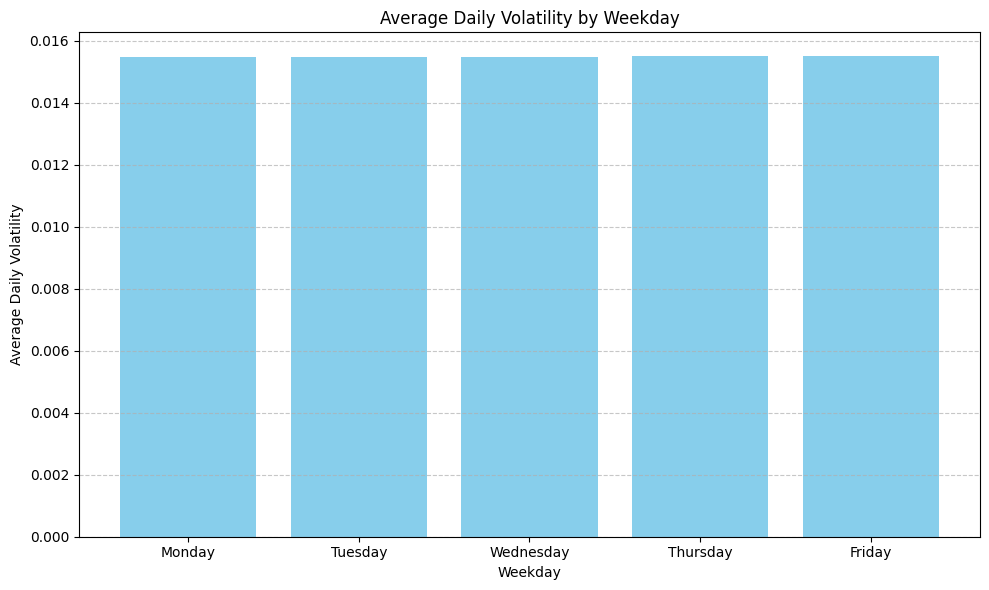

In [5]:
# Calculate daily returns. pct_change calculates percentage change row by row.
df['DailyReturn'] = df['Adj Close'].pct_change()

# Calculate rolling daily volatility
df['DailyVolatility'] = df['DailyReturn'].expanding().std()

# Add Weekday column
df['Weekday'] = df['Date'].dt.day_name()

# Group by Weekday and calculate mean of DailyVolatility
weekday_volatility = df.groupby('Weekday')['DailyVolatility'].mean()

# Define correct weekday order
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']

# Reorder the weekday_volatility Series to follow the weekday order
weekday_volatility = weekday_volatility.reindex(weekday_order)

# ✅ Print the average daily volatility by weekday
print("Average Daily Volatility by Weekday:")
print(weekday_volatility)

# Plotting
plt.figure(figsize=(10, 6))
plt.bar(weekday_volatility.index, weekday_volatility.values, color='skyblue')
plt.title('Average Daily Volatility by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Average Daily Volatility')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


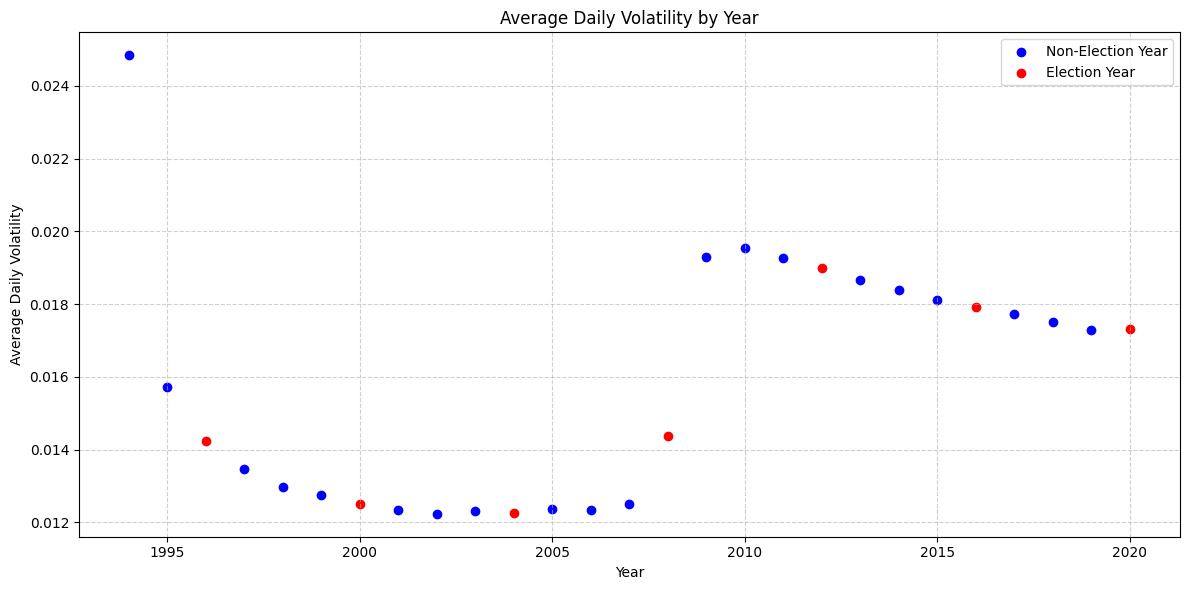

In [6]:
import matplotlib.pyplot as plt

# Extract year from date
df['Year'] = df['Date'].dt.year

# Group by year and compute the average volatility per year
yearly_volatility = df.groupby('Year')['DailyVolatility'].mean().reset_index()

# Merge election year info into the yearly_volatility DataFrame
# If even one day in the year was marked as Election Year, mark the whole year
election_years = df.groupby('Year')['Election Year'].any().reset_index()
yearly_volatility = pd.merge(yearly_volatility, election_years, on='Year')

# Plot
plt.figure(figsize=(12, 6))
for _, row in yearly_volatility.iterrows():
    if row['Election Year']:
        plt.scatter(row['Year'], row['DailyVolatility'], color='red', label='Election Year' if 'Election Year' not in plt.gca().get_legend_handles_labels()[1] else "")
    else:
        plt.scatter(row['Year'], row['DailyVolatility'], color='blue', label='Non-Election Year' if 'Non-Election Year' not in plt.gca().get_legend_handles_labels()[1] else "")

plt.title("Average Daily Volatility by Year")
plt.xlabel("Year")
plt.ylabel("Average Daily Volatility")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


/var/folders/11/dxk146610qn60jn0f0xly1800000gn/T/ipykernel_73465/1806909435.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_volatility = df.groupby(['Year', 'Month'])['DailyVolatility'].mean().reset_index()


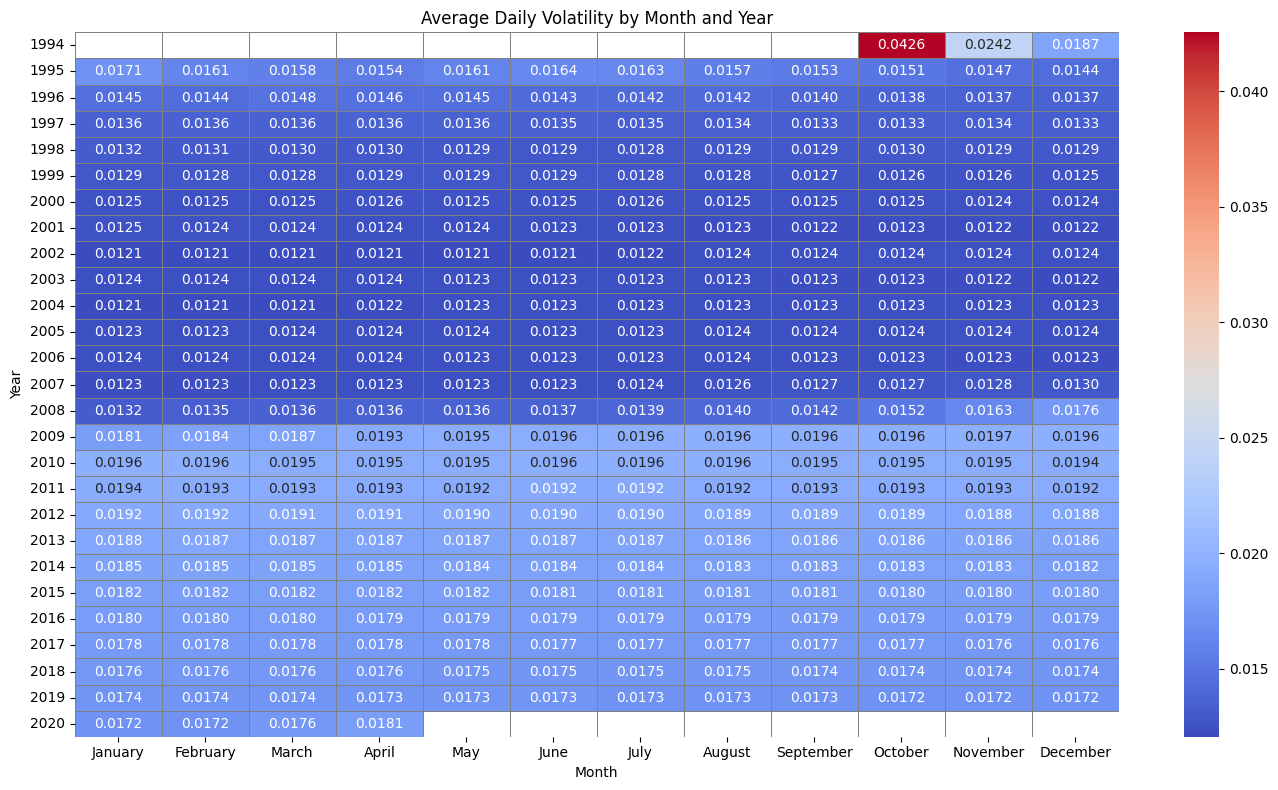

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Ensure Month is a categorical type to preserve correct order
df['Month'] = pd.Categorical(df['Month'], categories=[
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
], ordered=True)

# Extract Year
df['Year'] = df['Date'].dt.year

# Group by Year and Month and calculate average volatility
monthly_volatility = df.groupby(['Year', 'Month'])['DailyVolatility'].mean().reset_index()

# Pivot to format data for heatmap (Year as rows, Month as columns)
heatmap_data = monthly_volatility.pivot(index='Year', columns='Month', values='DailyVolatility')

# Plot heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(heatmap_data, cmap='coolwarm', annot=True, fmt=".4f", linewidths=.5, linecolor='gray')

plt.title("Average Daily Volatility by Month and Year")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


### Explain what you have learned from each of your graphs.

In [8]:
print("The bar chart shows the average volatility by weekday. There is no discernable difference between weekdays.")
print("The scatterplot shows volatility over years, with election years marked in red. There is no discernable difference between election years and non-election years. Overall volatility follows the smoothing trend, so if there was a slope/curve for volatility in 2006-7 and then continue 2009-11. The 2008 matches the volatility between 2007 and 2009.")
print("The heatmap shows average volatility by month and year. Volatility was mostly lower until the fall of 2008. From that point on, volatility has never returned to its pre-2008 levels.")

The bar chart shows the average volatility by weekday. There is no discernable difference between weekdays.
The scatterplot shows volatility over years, with election years marked in red. There is no discernable difference between election years and non-election years. Overall volatility follows the smoothing trend, so if there was a slope/curve for volatility in 2006-7 and then continue 2009-11. The 2008 matches the volatility between 2007 and 2009.
The heatmap shows average volatility by month and year. Volatility was mostly lower until the fall of 2008. From that point on, volatility has never returned to its pre-2008 levels.


### Write a conclusion that summarizes your findings.

The charts not only displayed the data, but also gave striking visualizations of the relationships between variables. They told a story about volatility over time. For example, the volatility vs weekday chart showed bars of the same height/value. I had to print the values to make sure they weren't the same because the numbers are so close. The volatility plotted year over year showed the volatility as part of trends. At times it rises or falls, but it only does so based on the trend of the previous and following year. It's better to see volatility as a trend. We plotted the election years just to see if they made a difference, but they really didn't. Finally the last chart shows a heatmap with the year and month. This chart was much easier to read for exact values. 